# Home Work 02

In [20]:


def f(x):
    return (x-1)**2+(1/x-2)**2

def df(x):
    return 2*(x-1) + 2*(1/x-2)*(-1/x**2)

def descente1(f, df, a, alpha=1e-2, eps=1e-9, maxIter=1000):
    for i in range(maxIter):
        g = df(a)  # gradient 
        if abs(g) < eps:
            break
        x_next = a - alpha * g # update the position 
        if not (float("-inf") < x_next < float("inf")):
            print("maxiter reached D1:", i)
            break
        # stop if update is tiny
        if abs(x_next - a) < eps:
            a = x_next
            print("maxiter reached D1:", i)
            break
        a = x_next
    return a

def descente2(f, a, lr=1e-2, eps=1e-9, maxIter=1000):
    # finite-difference step for numerical derivative
    h = 1e-6

    for i in range(maxIter):
        # numerical derivative: central difference
        # central difference
        g = (f(a + h) - f(a - h)) / (2 * h)

        if abs(g) < eps:
            break

        a_next = a - lr * g
        if not (float("-inf") < a_next < float("inf")):
            print("maxiter reached D2:", i)
            break
        if abs(a_next - a) < eps:
            a = a_next
            print("maxiter reached D2:", i)
            break
        a = a_next

    return a

print("Decente 1")
print("Descente 1:", descente1(f, df, 1))
print("Decente 2")
print("Descente 2:", descente2(f, 1))

Decente 1
maxiter reached D1: 88
Descente 1: 0.5356873899132174
Decente 2
maxiter reached D2: 88
Descente 2: 0.5356873899149397


In [18]:
# check the minimum value of the function
print("f(Descente 1):", f(descente1(f, df, 1)))
print("f(Descente 2):", f(descente2(f, 1)))

maxiter reached: 88
f(Descente 1): 0.23333899401246838
maxiter reached: 88
f(Descente 2): 0.2333389940124684


<b>The both function follow the same logic :</b>
- “Compute how the function changes” at current x (either df(x) or numerical approx).
- “Move downhill” opposite the sign of that change.
- Stop when the downhill direction becomes useless (derivative ~ 0) or steps become tiny.

<b> Approximative function in decente 2 </b>
we used the central difference for the numerical derivative in descente2, which is an approximately second-order accurate method, meaning the error decreases quadratically as the step size h decreases.

Starting from a=1, both gradient descent with analytical derivative and gradient descent with numerical derivative converge to the same minimizer x* ≈ 0.5356873899. The two results differ only by about 1.7×10^-12, which is attributed to the finite-difference approximation used in descente2.

## Graphical interpretation

maxiter reached D1: 88
maxiter reached D1: 88
maxiter reached D2: 88
maxiter reached D2: 88


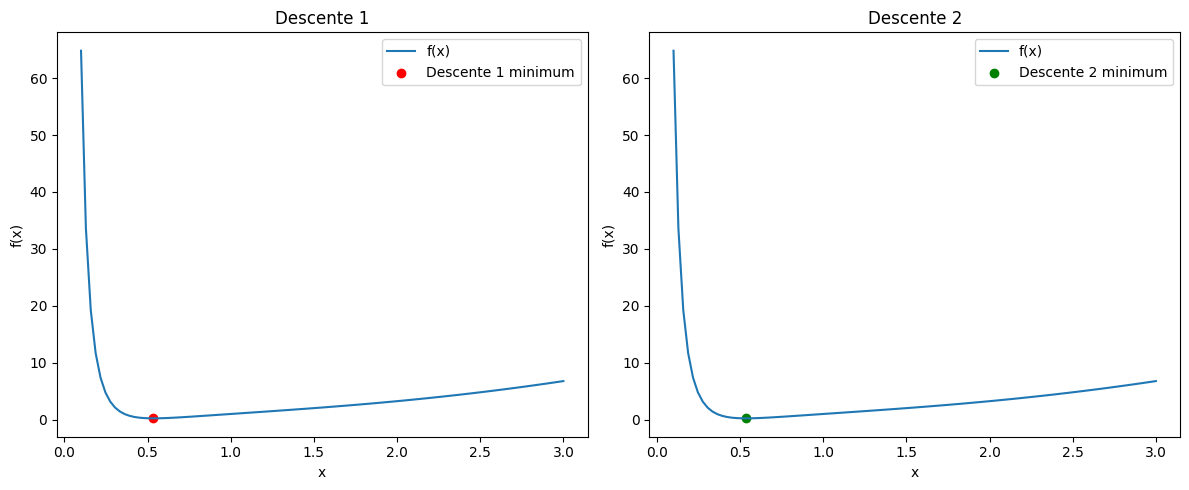

In [37]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0.1, 3, 100)
# plot each minimum in a different graph but in the same figure
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(x, f(x), label='f(x)')
plt.scatter(descente1(f, df, 1), f(descente1(f, df, 1)), color='red', label='Descente 1 minimum')
plt.title('Descente 1')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()        
plt.subplot(1, 2, 2)
plt.plot(x, f(x), label='f(x)')
plt.scatter(descente2(f, 1), f(descente2(f, 1)),
            color='green', label='Descente 2 minimum')
plt.title('Descente 2')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.tight_layout()
plt.show()


In this graphic, both methods found the same minimum, which is around x=1.5 with f(x) close to 0.

## Trying different parameter to see the convergence behavior

In [24]:
# try diffirent alpha eps and maxIter and see the effect on convergence
alphas = [1e-3, 1e-2, 1e-1]
epsilons = [1e-9, 1e-6, 1e-3]
maxIters = [1000, 5000, 10000]  
results = []
for alpha in alphas:
    for eps in epsilons:
        for maxIter in maxIters:
            res = descente1(f, df, 1, alpha=alpha, eps=eps, maxIter=maxIter)
            results.append((alpha, eps, maxIter, res, f(res)))
            print(f"alpha: {alpha}, eps: {eps}, maxIter: {maxIter}, result: {res}, f(result): {f(res)}")
                                                                                                            



maxiter reached D1: 856
alpha: 0.001, eps: 1e-09, maxIter: 1000, result: 0.5356874295806006, f(result): 0.23333899401248914
maxiter reached D1: 856
alpha: 0.001, eps: 1e-09, maxIter: 5000, result: 0.5356874295806006, f(result): 0.23333899401248914
maxiter reached D1: 856
alpha: 0.001, eps: 1e-09, maxIter: 10000, result: 0.5356874295806006, f(result): 0.23333899401248914
maxiter reached D1: 557
alpha: 0.001, eps: 1e-06, maxIter: 1000, result: 0.5357299368867198, f(result): 0.23333901466764168
maxiter reached D1: 557
alpha: 0.001, eps: 1e-06, maxIter: 5000, result: 0.5357299368867198, f(result): 0.23333901466764168
maxiter reached D1: 557
alpha: 0.001, eps: 1e-06, maxIter: 10000, result: 0.5357299368867198, f(result): 0.23333901466764168
maxiter reached D1: 229
alpha: 0.001, eps: 0.001, maxIter: 1000, result: 0.5941214942793104, f(result): 0.2651265834832285
maxiter reached D1: 229
alpha: 0.001, eps: 0.001, maxIter: 5000, result: 0.5941214942793104, f(result): 0.2651265834832285
maxiter 

alpha=0.001, eps=1e-09, maxIter=1000 -> x=0.5356874295806006, f(x)=0.23333899401248914


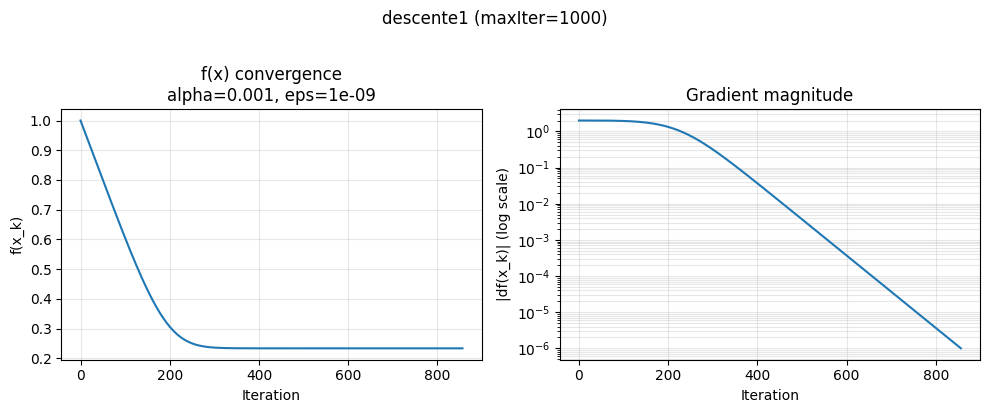

alpha=0.001, eps=1e-09, maxIter=5000 -> x=0.5356874295806006, f(x)=0.23333899401248914


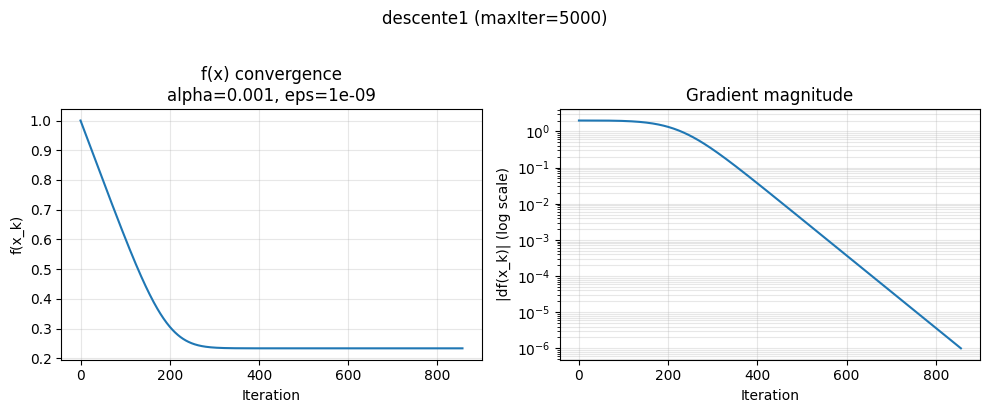

alpha=0.001, eps=1e-09, maxIter=10000 -> x=0.5356874295806006, f(x)=0.23333899401248914


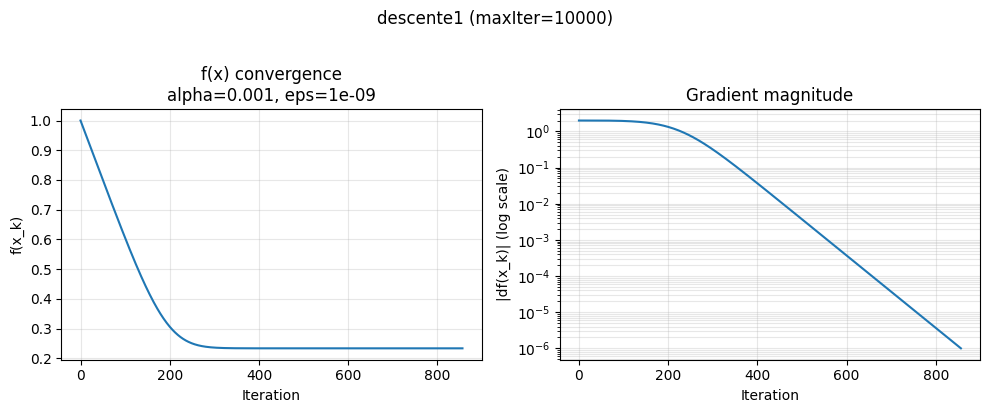

alpha=0.001, eps=1e-06, maxIter=1000 -> x=0.5357299368867198, f(x)=0.23333901466764168


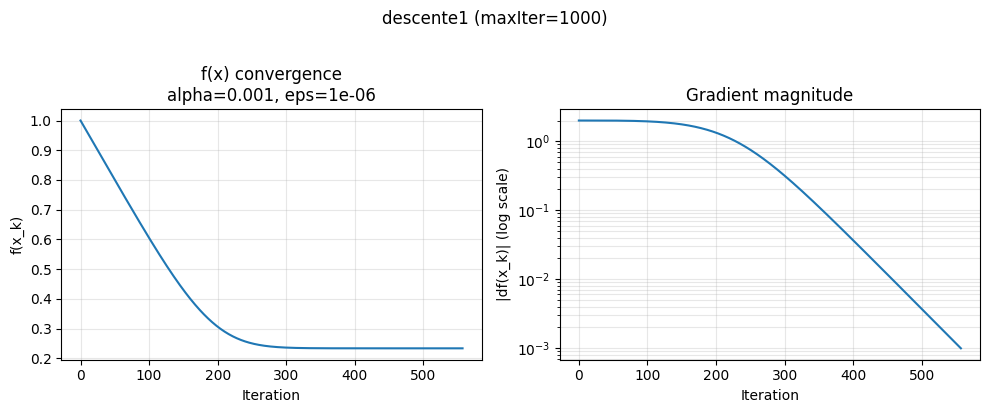

alpha=0.001, eps=1e-06, maxIter=5000 -> x=0.5357299368867198, f(x)=0.23333901466764168


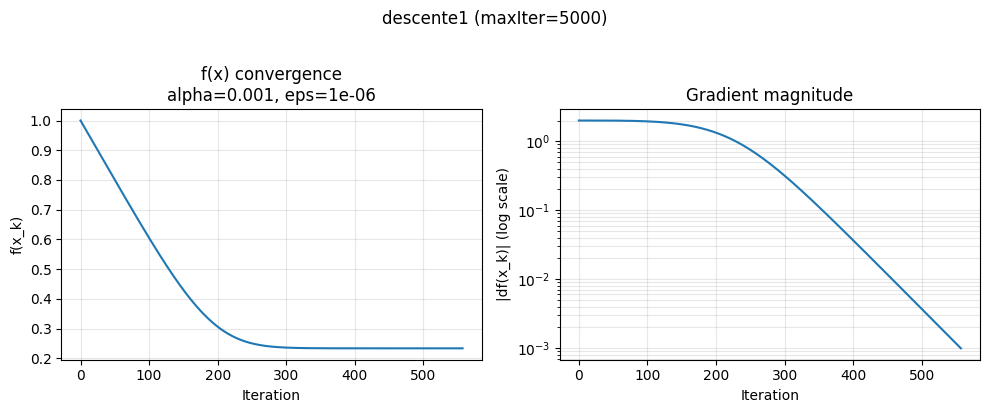

alpha=0.001, eps=1e-06, maxIter=10000 -> x=0.5357299368867198, f(x)=0.23333901466764168


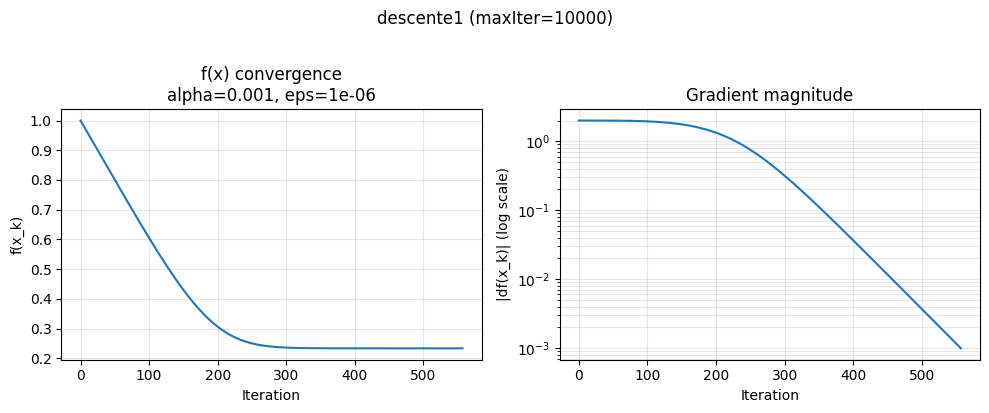

alpha=0.001, eps=0.001, maxIter=1000 -> x=0.5941214942793104, f(x)=0.2651265834832285


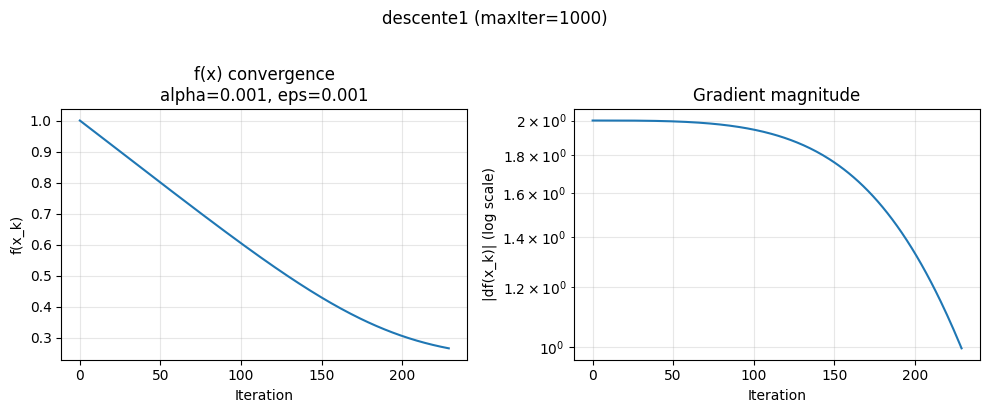

alpha=0.001, eps=0.001, maxIter=5000 -> x=0.5941214942793104, f(x)=0.2651265834832285


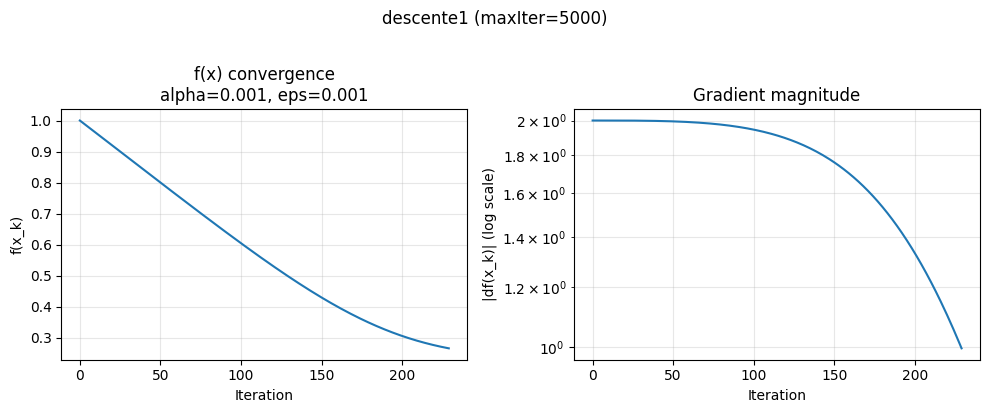

alpha=0.001, eps=0.001, maxIter=10000 -> x=0.5941214942793104, f(x)=0.2651265834832285


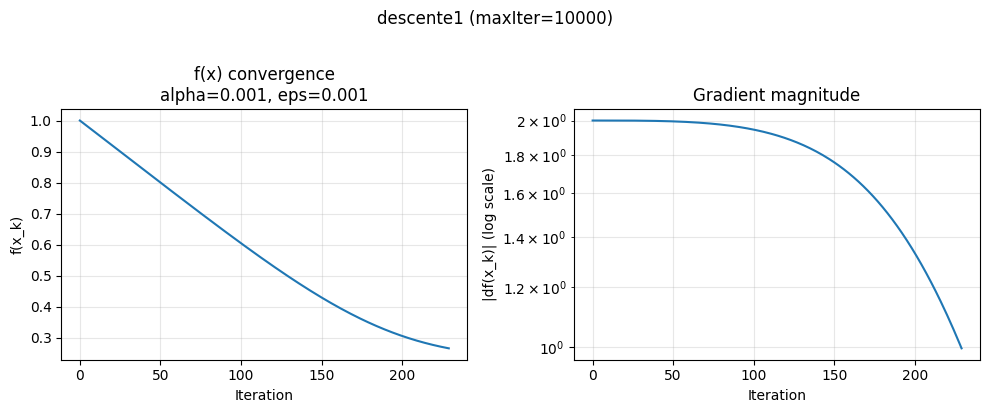

alpha=0.01, eps=1e-09, maxIter=1000 -> x=0.5356873899132174, f(x)=0.23333899401246838


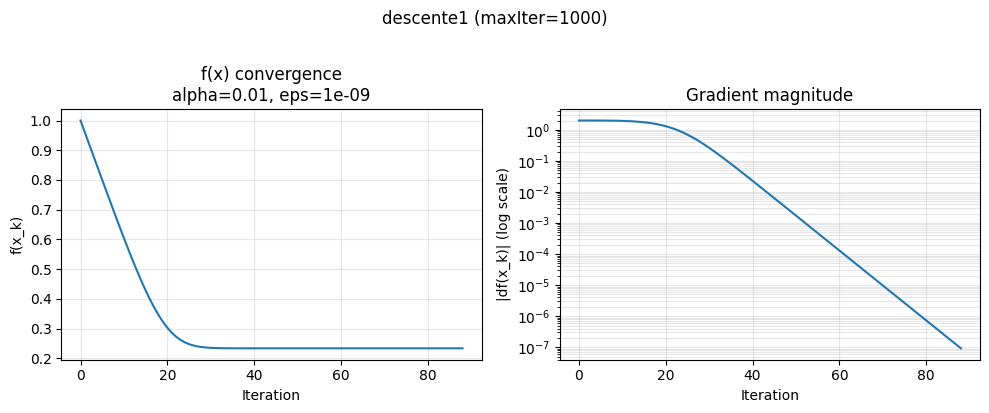

alpha=0.01, eps=1e-09, maxIter=5000 -> x=0.5356873899132174, f(x)=0.23333899401246838


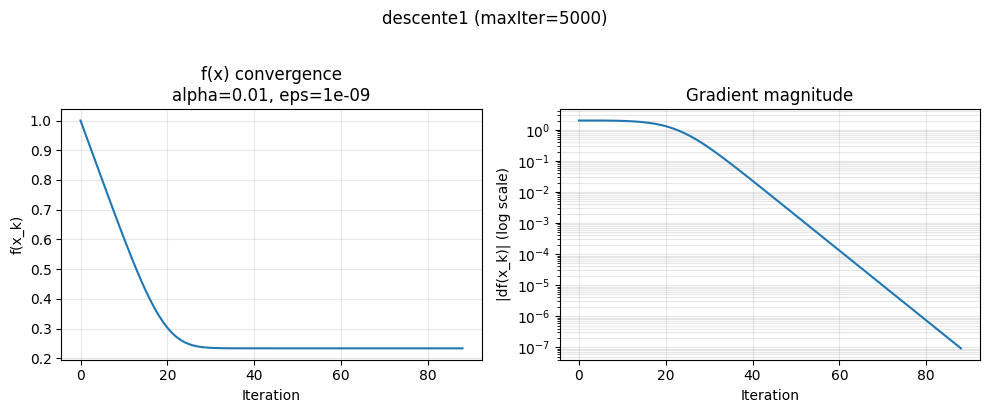

alpha=0.01, eps=1e-09, maxIter=10000 -> x=0.5356873899132174, f(x)=0.23333899401246838


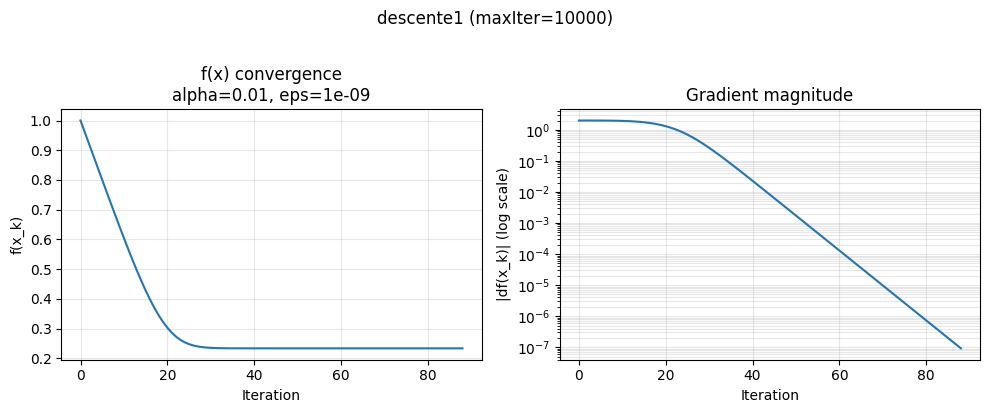

alpha=0.01, eps=1e-06, maxIter=1000 -> x=0.5356900127555813, f(x)=0.23333899409114917


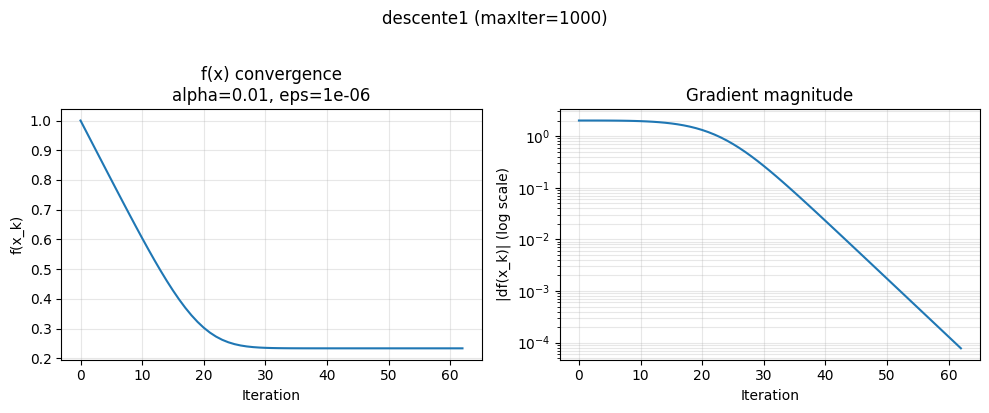

alpha=0.01, eps=1e-06, maxIter=5000 -> x=0.5356900127555813, f(x)=0.23333899409114917


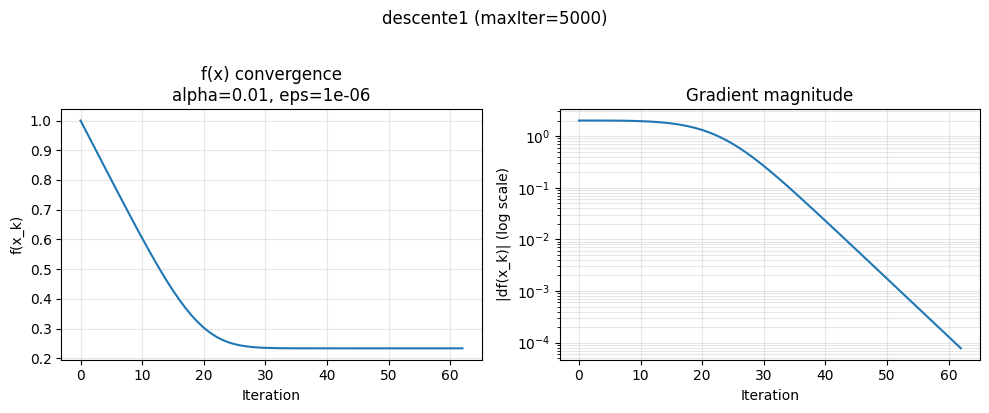

alpha=0.01, eps=1e-06, maxIter=10000 -> x=0.5356900127555813, f(x)=0.23333899409114917


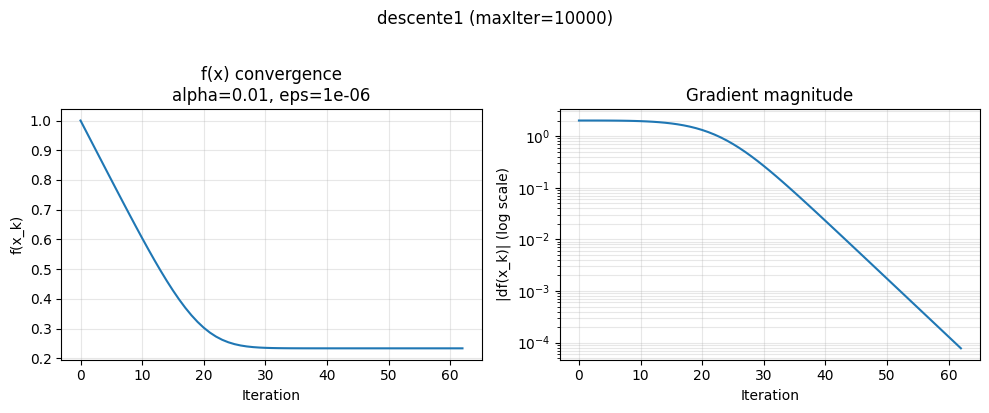

alpha=0.01, eps=0.001, maxIter=1000 -> x=0.5384928233025237, f(x)=0.2334278760524857


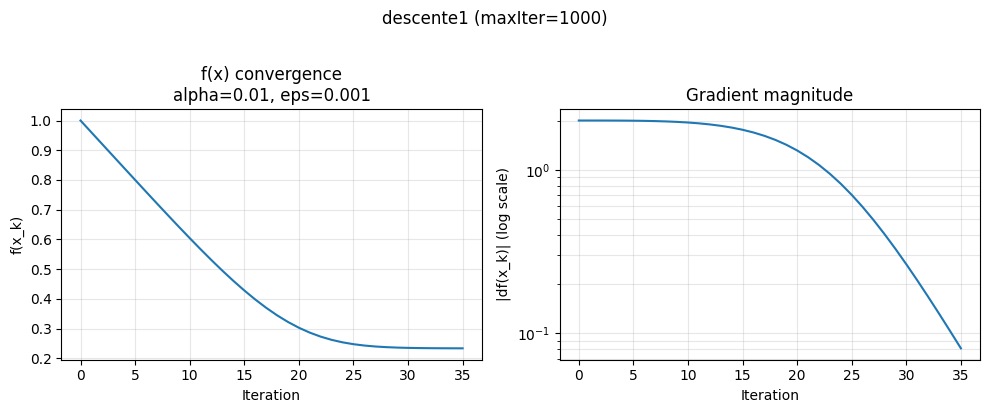

alpha=0.01, eps=0.001, maxIter=5000 -> x=0.5384928233025237, f(x)=0.2334278760524857


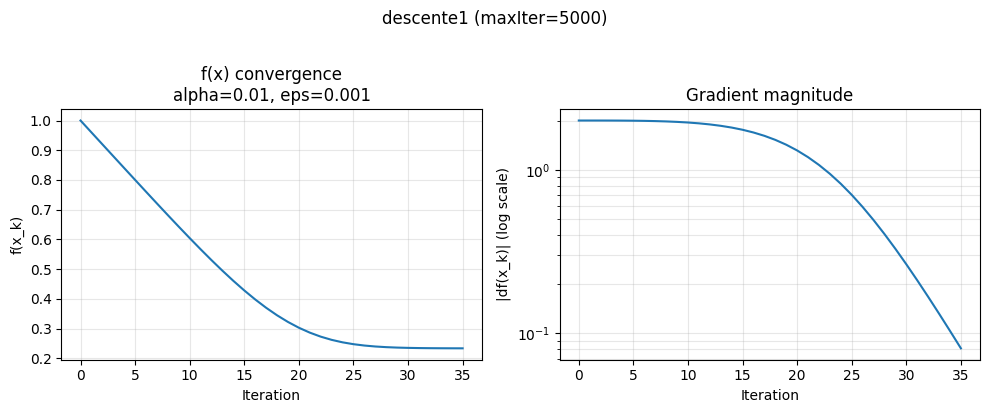

alpha=0.01, eps=0.001, maxIter=10000 -> x=0.5384928233025237, f(x)=0.2334278760524857


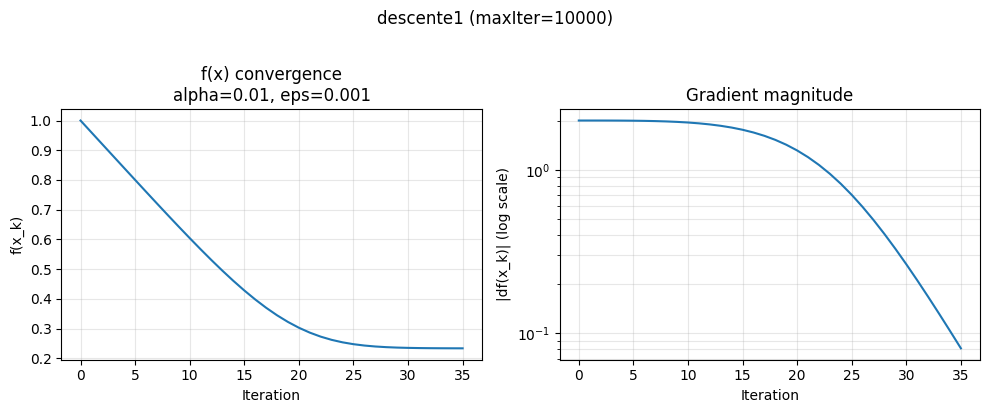

alpha=0.1, eps=1e-09, maxIter=1000 -> x=0.6145222499185753, f(x)=0.2875130113846983


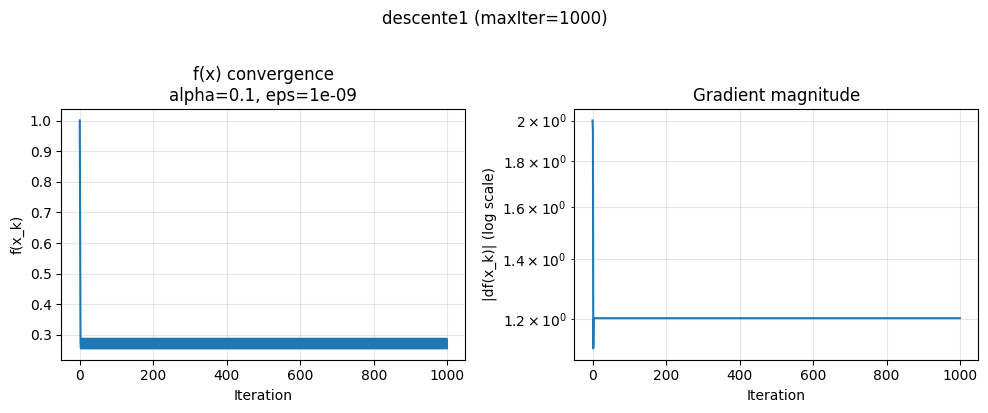

alpha=0.1, eps=1e-09, maxIter=5000 -> x=0.6145222499185753, f(x)=0.2875130113846983


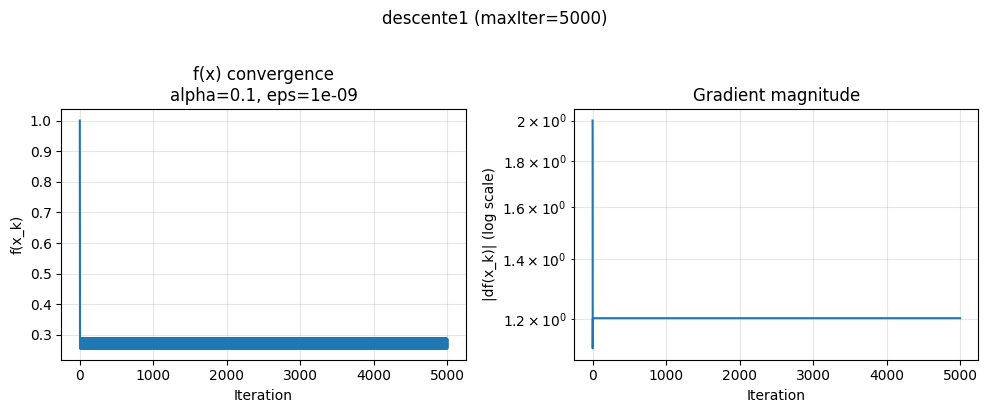

alpha=0.1, eps=1e-09, maxIter=10000 -> x=0.6145222499185753, f(x)=0.2875130113846983


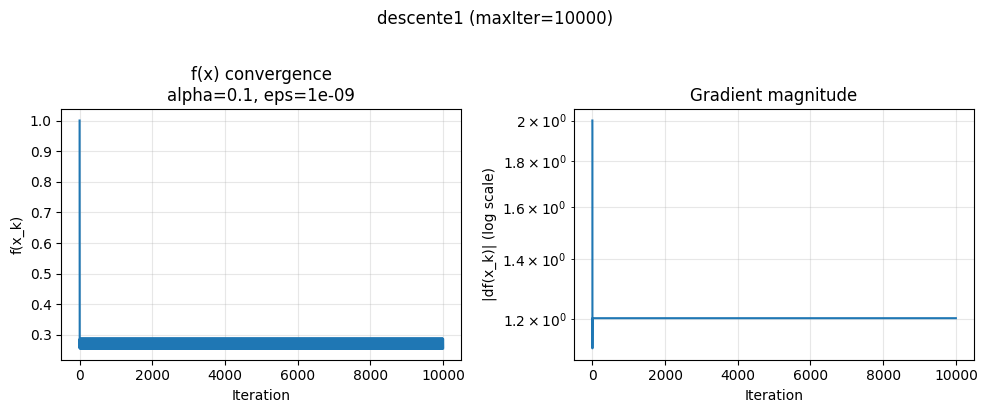

alpha=0.1, eps=1e-06, maxIter=1000 -> x=0.6145222499185753, f(x)=0.2875130113846983


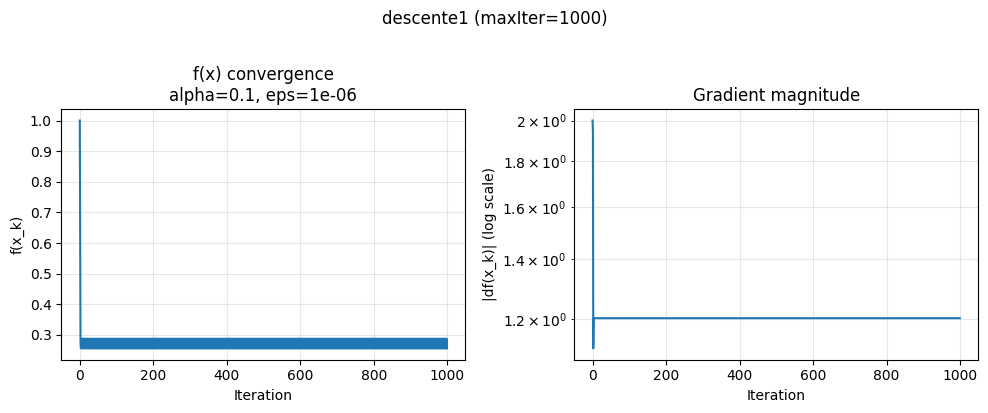

alpha=0.1, eps=1e-06, maxIter=5000 -> x=0.6145222499185753, f(x)=0.2875130113846983


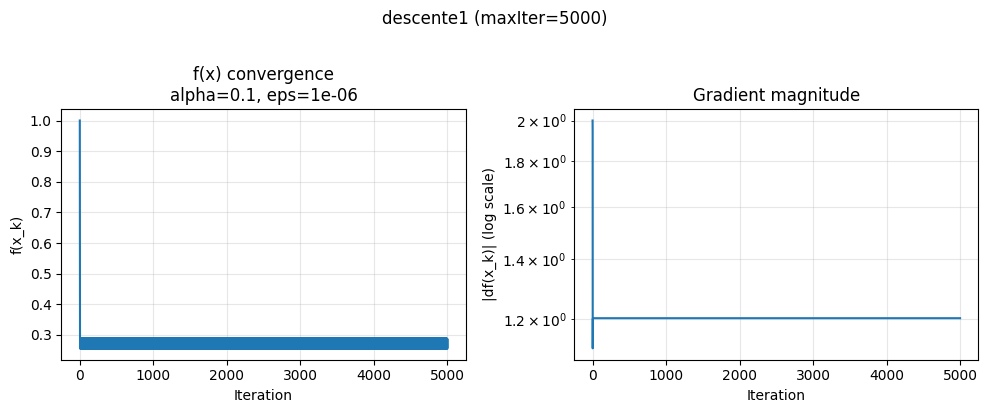

alpha=0.1, eps=1e-06, maxIter=10000 -> x=0.6145222499185753, f(x)=0.2875130113846983


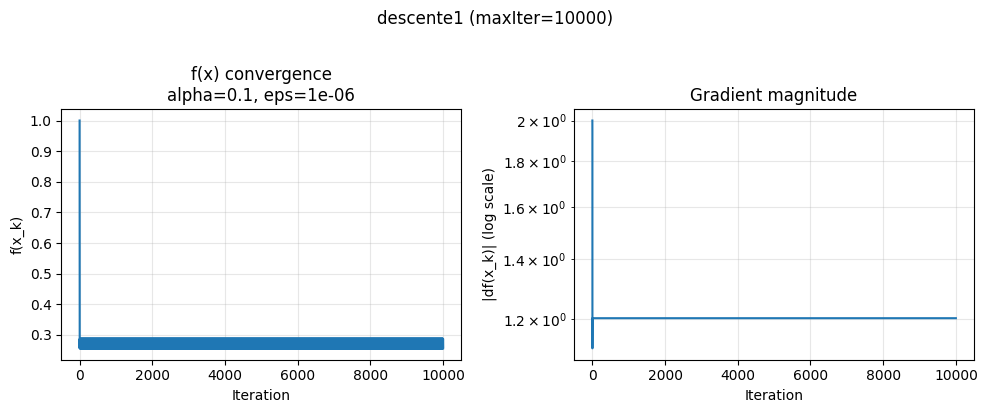

alpha=0.1, eps=0.001, maxIter=1000 -> x=0.6145222499185753, f(x)=0.2875130113846983


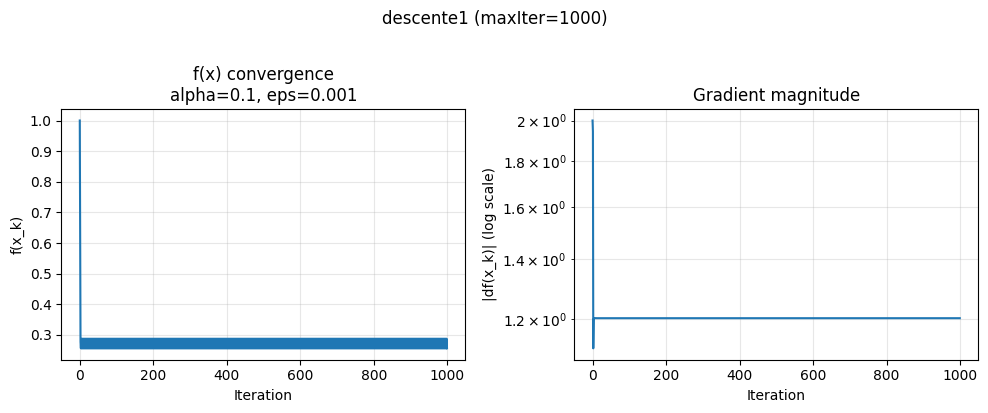

alpha=0.1, eps=0.001, maxIter=5000 -> x=0.6145222499185753, f(x)=0.2875130113846983


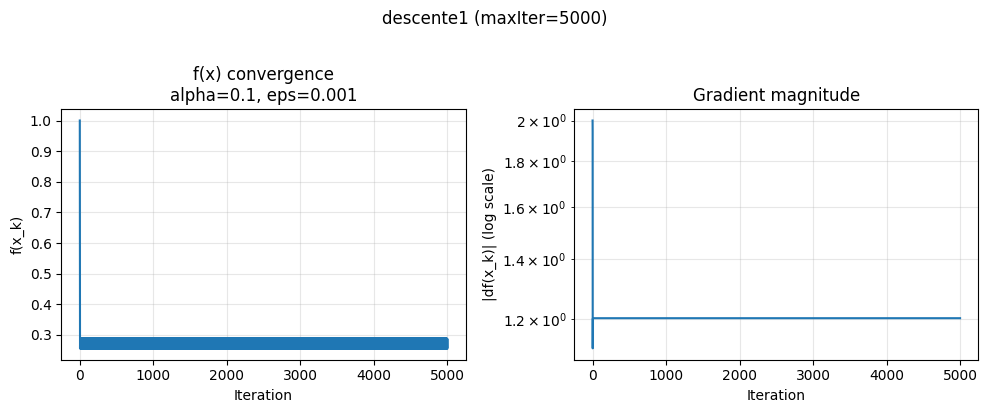

alpha=0.1, eps=0.001, maxIter=10000 -> x=0.6145222499185753, f(x)=0.2875130113846983


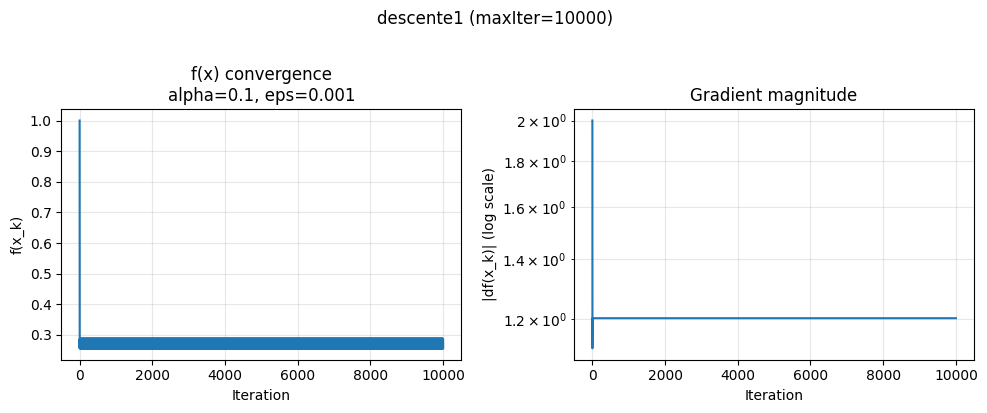

In [29]:
# graphic showing the convergence over iterations for different parameters each parameter in a different figure
import matplotlib.pyplot as plt

def descente1_history(f, df, a, alpha, eps, maxIter):
    x = float(a)

    it_hist = []
    fs_hist = []
    gabs_hist = []

    for k in range(maxIter):
        g = df(x)
        it_hist.append(k)
        fs_hist.append(f(x))
        gabs_hist.append(abs(g))

        # stop when gradient is small
        if abs(g) < eps:
            break

        # gradient descent update
        x_next = x - alpha * g

        # safety checks
        if not math.isfinite(x_next):
            break
        if abs(x_next - x) < eps:
            x = x_next
            break

        x = x_next

    return x, {"it": it_hist, "f": fs_hist, "gabs": gabs_hist}

alphas = [1e-3, 1e-2, 1e-1]
epsilons = [1e-9, 1e-6, 1e-3]
maxIters = [1000, 5000, 10000]

results = []

for alpha in alphas:
    for eps in epsilons:
        for maxIter in maxIters:
            x_star, hist = descente1_history(f, df, 1, alpha=alpha, eps=eps, maxIter=maxIter)
            fx = f(x_star)

            results.append((alpha, eps, maxIter, x_star, fx))
            print(f"alpha={alpha}, eps={eps}, maxIter={maxIter} -> x={x_star}, f(x)={fx}")

            # ---- plot convergence for this parameter set ----
            it = hist["it"]
            f_hist = hist["f"]
            gabs_hist = hist["gabs"]

            plt.figure(figsize=(10, 4))

            plt.subplot(1, 2, 1)
            plt.plot(it, f_hist)
            plt.xlabel("Iteration")
            plt.ylabel("f(x_k)")
            plt.grid(True, alpha=0.3)
            plt.title(f"f(x) convergence\nalpha={alpha}, eps={eps}")

            plt.subplot(1, 2, 2)
            plt.semilogy(it, gabs_hist)
            plt.xlabel("Iteration")
            plt.ylabel("|df(x_k)| (log scale)")
            plt.grid(True, which="both", alpha=0.3)
            plt.title("Gradient magnitude")

            plt.suptitle(f"descente1 (maxIter={maxIter})", y=1.02)
            plt.tight_layout()
            plt.show()

we see different convergence behaviors for different parameters, some converge faster than others, and some do not converge within the maxIter limit. The choice of alpha and eps has a significant impact on the convergence speed and stability.

if alpha is too small, convergence is very slow. If alpha is too large, it may diverge or oscillate. A smaller eps leads to more precise convergence but may require more iterations. The maxIter limit can prevent infinite loops but may stop before convergence if set too low.

the best parameters for this function seem to be alpha=1e-2, eps=1e-9, maxIter=1000, which gives a good balance of convergence speed and precision.

the good practice is to start with a moderate learning rate (like 1e-2), a small tolerance (like 1e-9), and a reasonable maxIter (like 1000) and then adjust based on the observed convergence behavior.

In [30]:
# Trying different g function in the decente 2 diffent from  g = (f(a + h) - f(a - h)) / (2 * h)
def descente2(f, a, lr=1e-2, eps=1e-9, maxIter=1000):
    # finite-difference step for numerical derivative
    h = 1e-6

    for i in range(maxIter):
        # numerical derivative: central difference
        # using forward difference instead 
        g = (f(a + h) - f(a)) / h

        if abs(g) < eps:
            break

        a_next = a - lr * g
        if not (float("-inf") < a_next < float("inf")):
            print("maxiter reached D2:", i)
            break
        if abs(a_next - a) < eps:
            a = a_next
            print("maxiter reached D2:", i)
            break
        a = a_next

    return a

alpha=0.001, eps=1e-09, maxIter=1000 -> x=0.5356874295806006, f(x)=0.23333899401248914


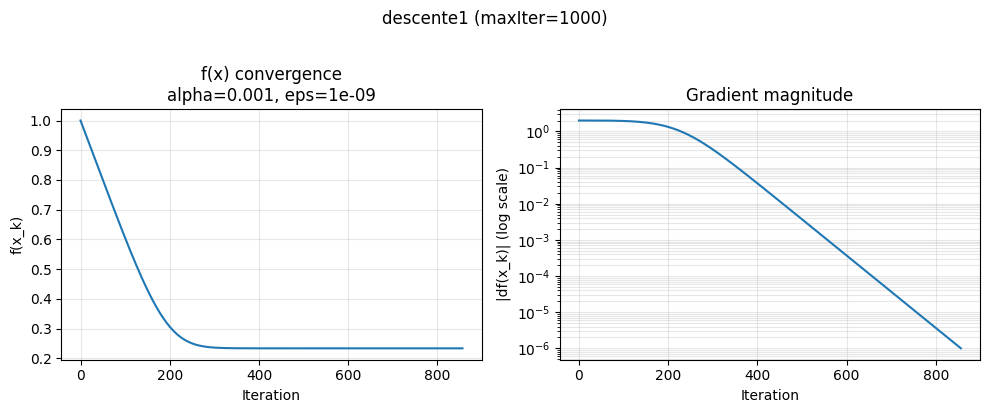

alpha=0.001, eps=1e-09, maxIter=5000 -> x=0.5356874295806006, f(x)=0.23333899401248914


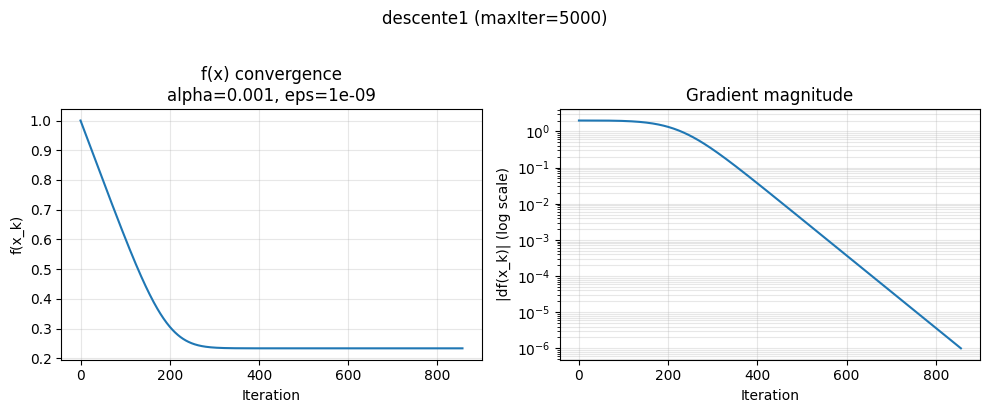

alpha=0.001, eps=1e-09, maxIter=10000 -> x=0.5356874295806006, f(x)=0.23333899401248914


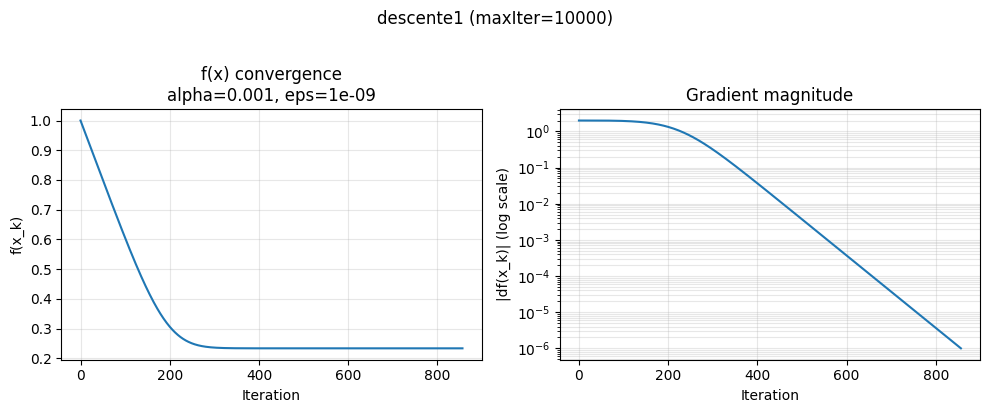

alpha=0.001, eps=1e-06, maxIter=1000 -> x=0.5357299368867198, f(x)=0.23333901466764168


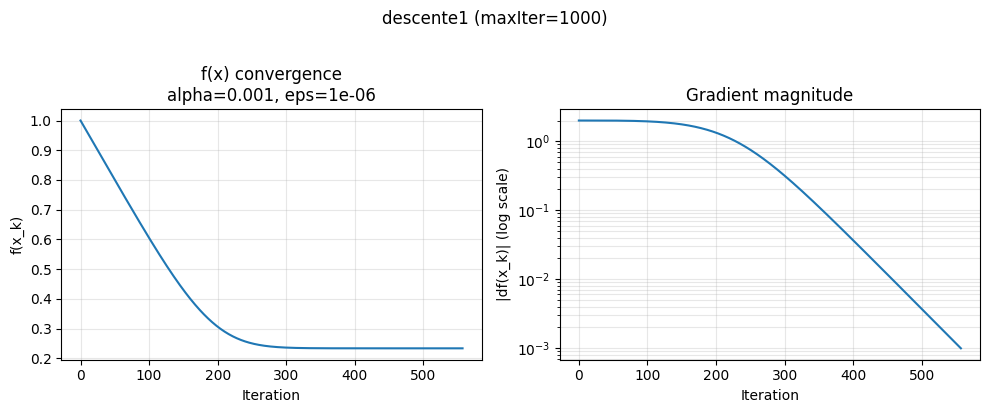

alpha=0.001, eps=1e-06, maxIter=5000 -> x=0.5357299368867198, f(x)=0.23333901466764168


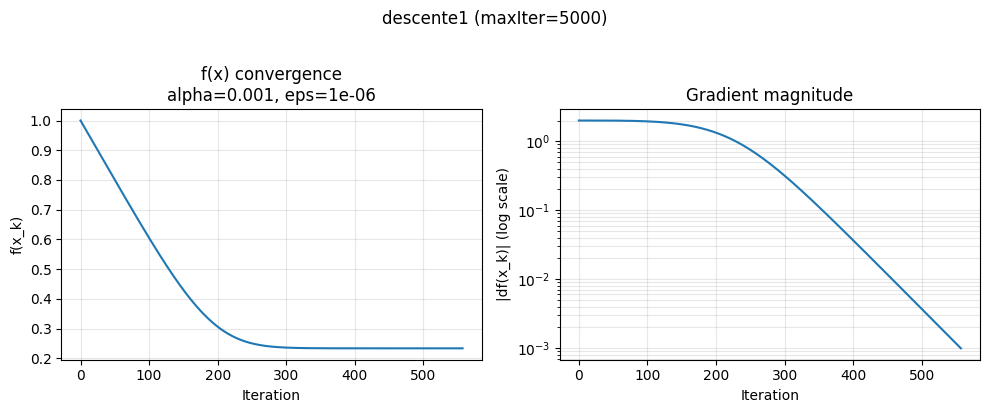

alpha=0.001, eps=1e-06, maxIter=10000 -> x=0.5357299368867198, f(x)=0.23333901466764168


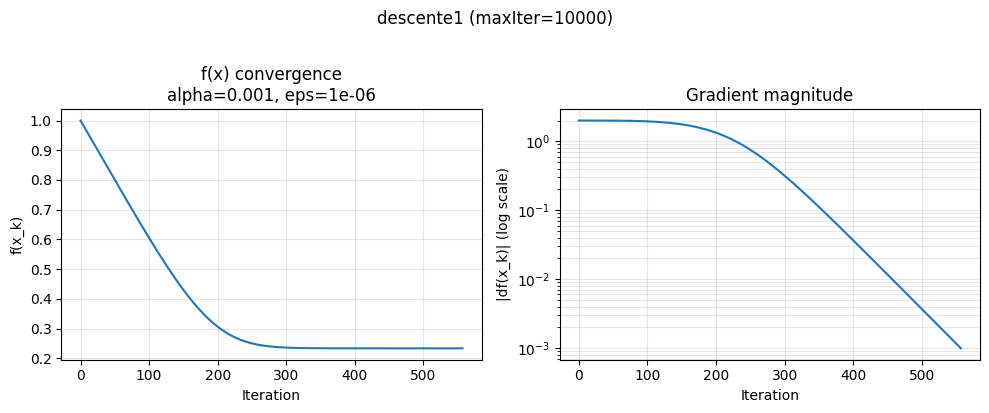

alpha=0.001, eps=0.001, maxIter=1000 -> x=0.5941214942793104, f(x)=0.2651265834832285


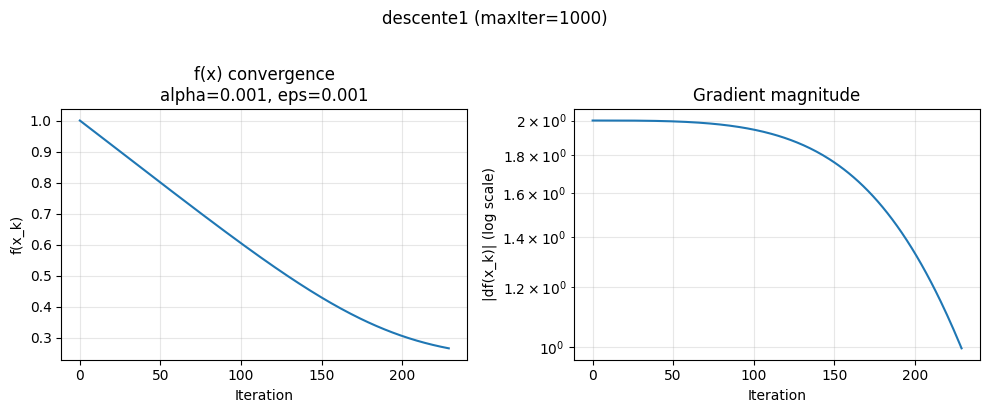

alpha=0.001, eps=0.001, maxIter=5000 -> x=0.5941214942793104, f(x)=0.2651265834832285


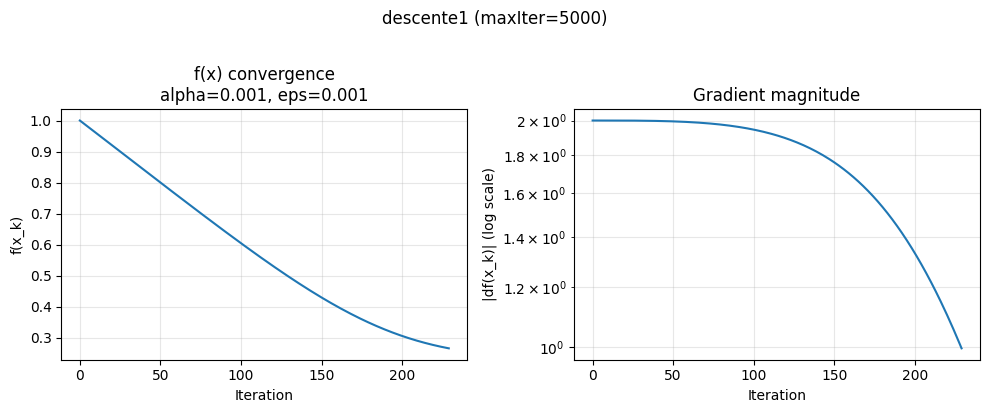

alpha=0.001, eps=0.001, maxIter=10000 -> x=0.5941214942793104, f(x)=0.2651265834832285


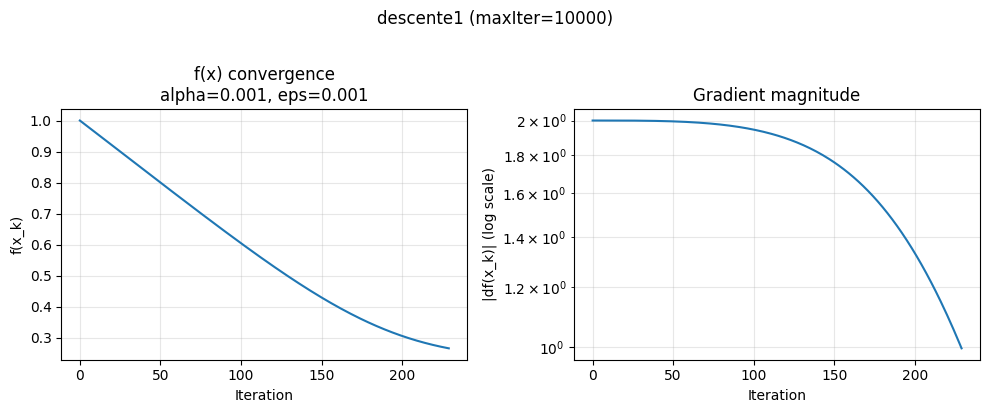

alpha=0.01, eps=1e-09, maxIter=1000 -> x=0.5356873899132174, f(x)=0.23333899401246838


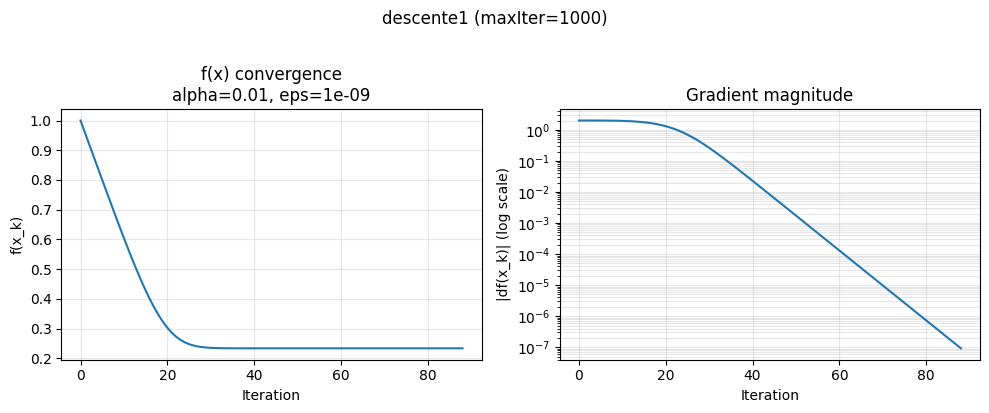

alpha=0.01, eps=1e-09, maxIter=5000 -> x=0.5356873899132174, f(x)=0.23333899401246838


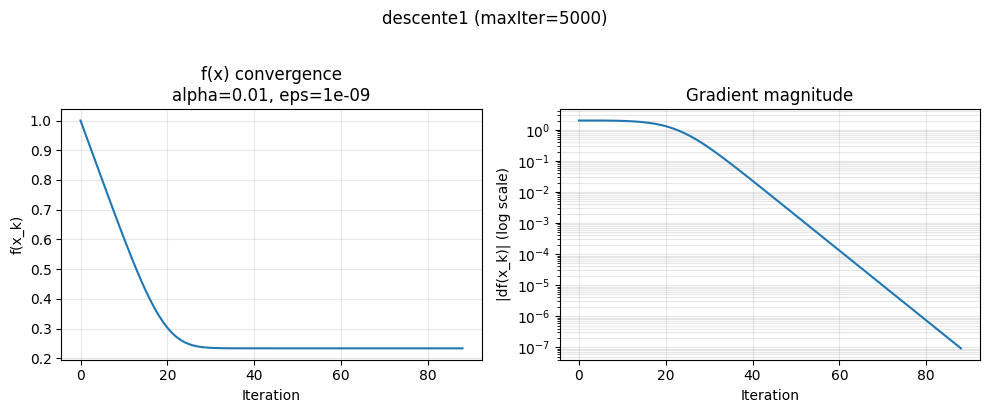

alpha=0.01, eps=1e-09, maxIter=10000 -> x=0.5356873899132174, f(x)=0.23333899401246838


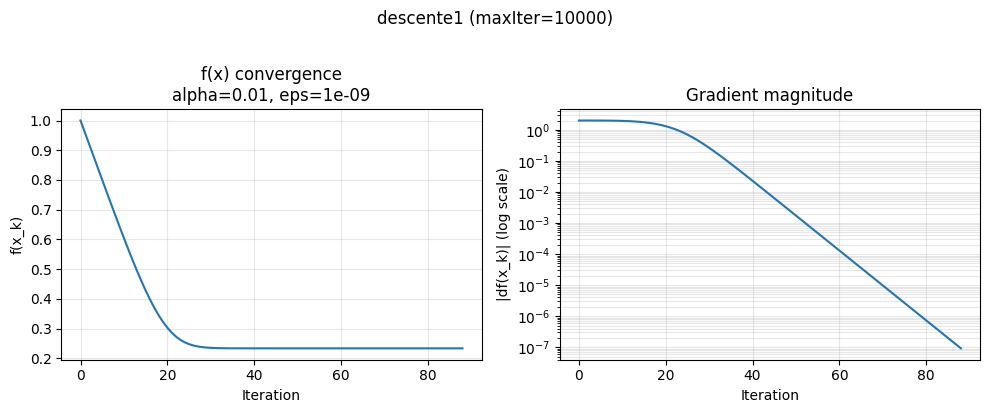

alpha=0.01, eps=1e-06, maxIter=1000 -> x=0.5356900127555813, f(x)=0.23333899409114917


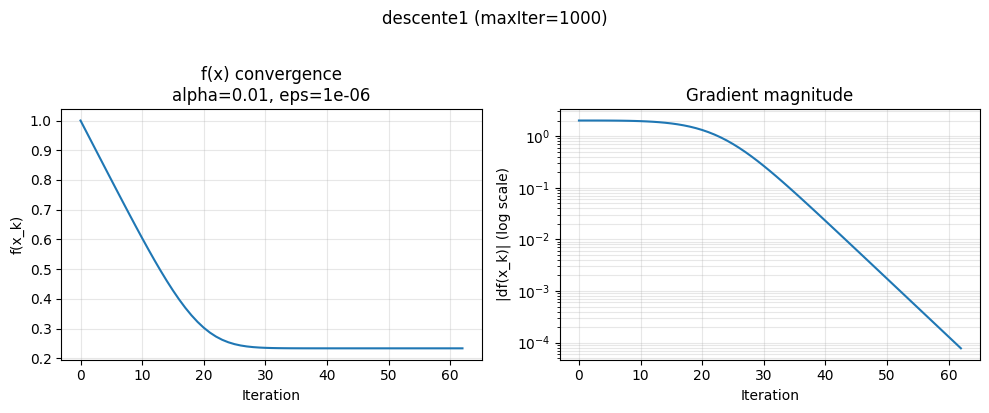

alpha=0.01, eps=1e-06, maxIter=5000 -> x=0.5356900127555813, f(x)=0.23333899409114917


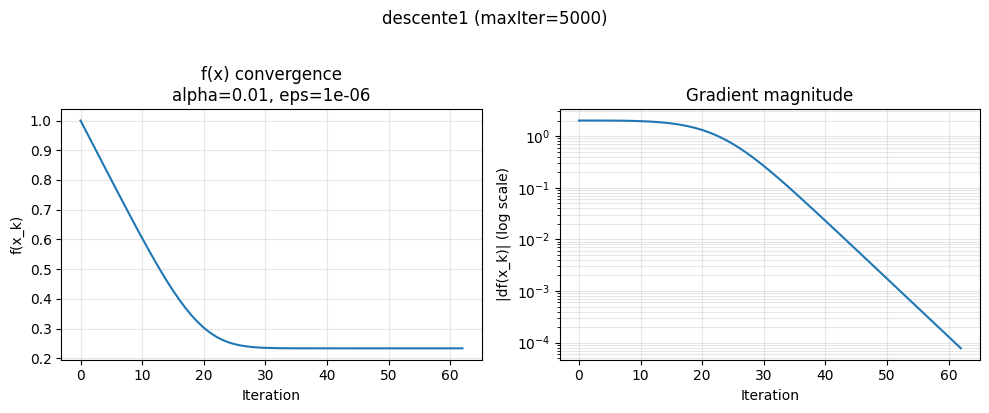

alpha=0.01, eps=1e-06, maxIter=10000 -> x=0.5356900127555813, f(x)=0.23333899409114917


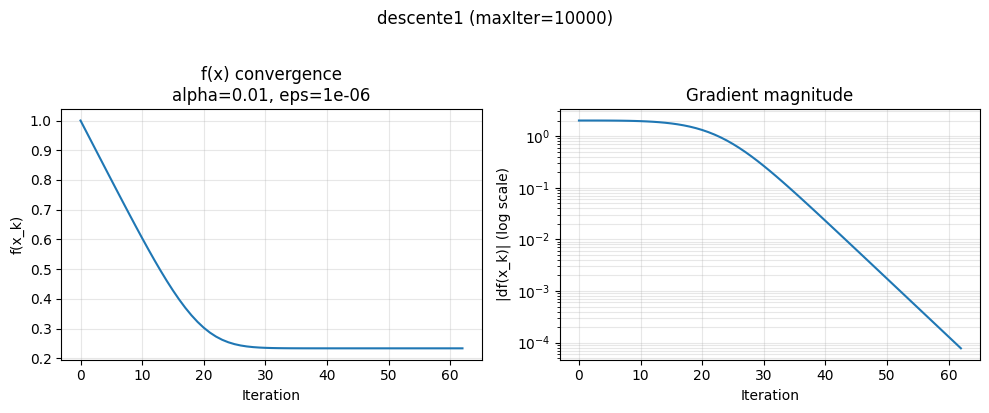

alpha=0.01, eps=0.001, maxIter=1000 -> x=0.5384928233025237, f(x)=0.2334278760524857


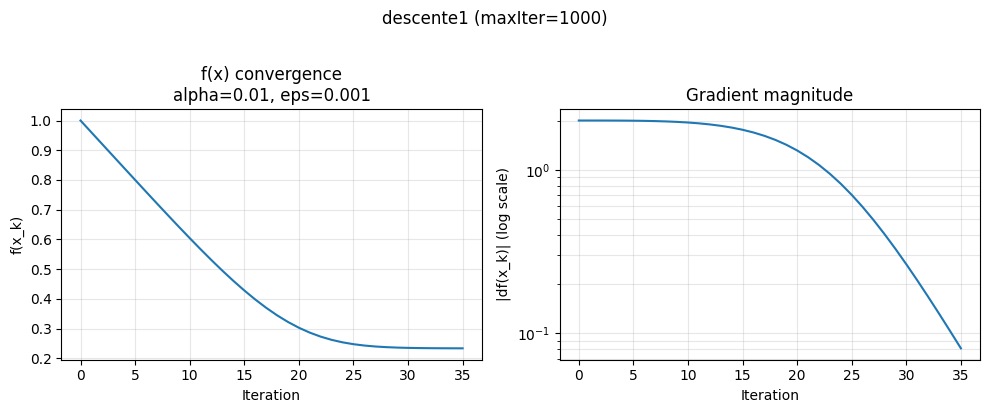

alpha=0.01, eps=0.001, maxIter=5000 -> x=0.5384928233025237, f(x)=0.2334278760524857


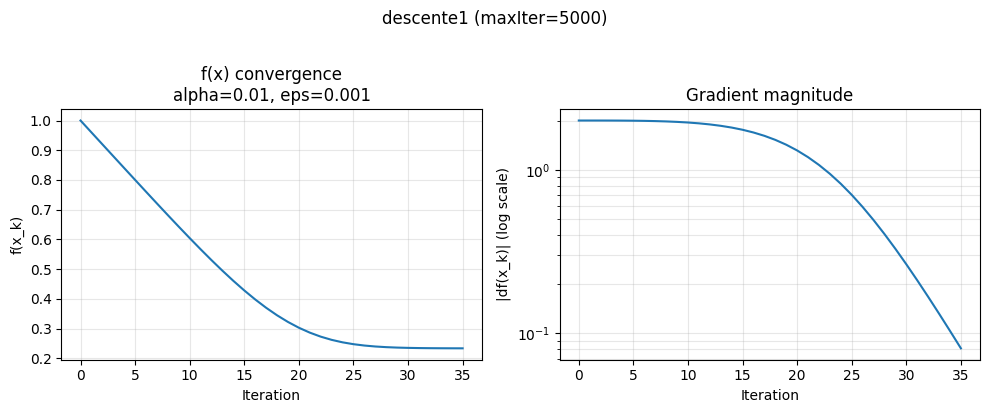

alpha=0.01, eps=0.001, maxIter=10000 -> x=0.5384928233025237, f(x)=0.2334278760524857


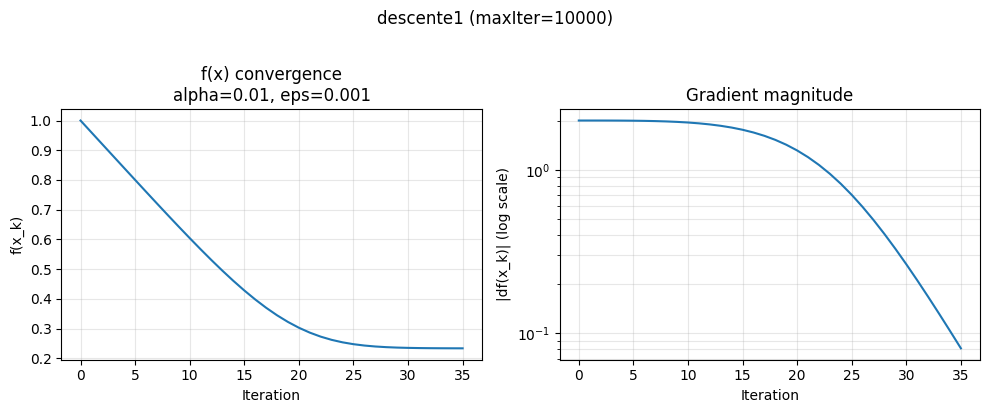

alpha=0.1, eps=1e-09, maxIter=1000 -> x=0.6145222499185753, f(x)=0.2875130113846983


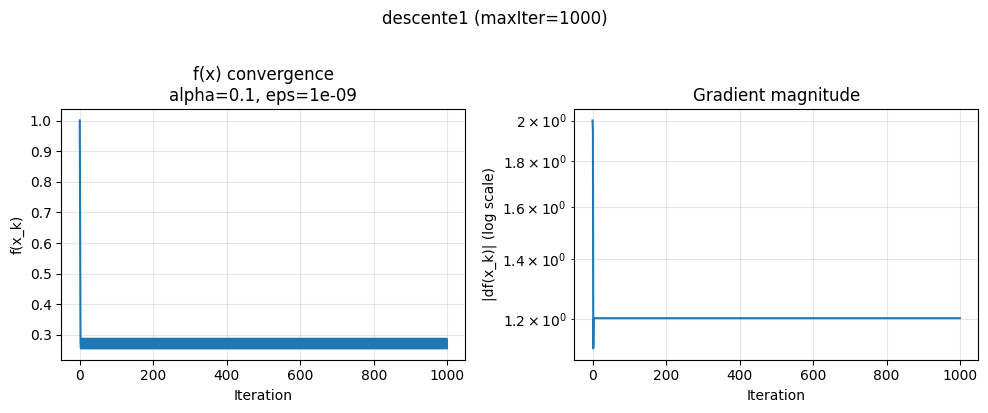

alpha=0.1, eps=1e-09, maxIter=5000 -> x=0.6145222499185753, f(x)=0.2875130113846983


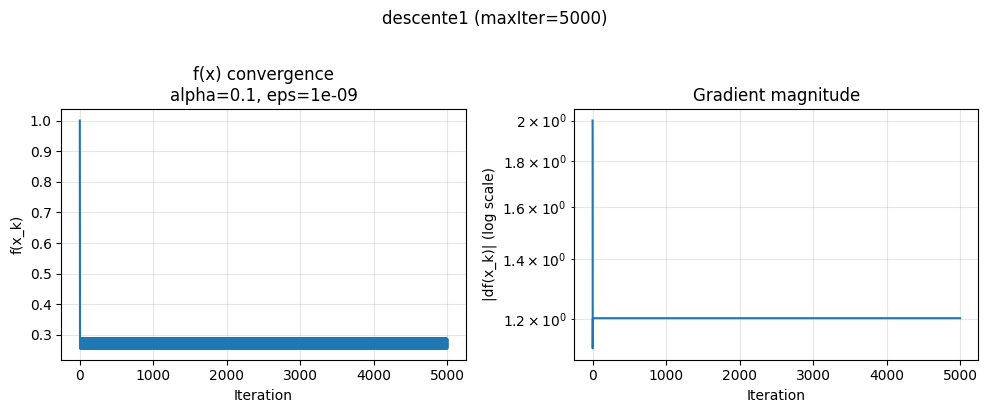

alpha=0.1, eps=1e-09, maxIter=10000 -> x=0.6145222499185753, f(x)=0.2875130113846983


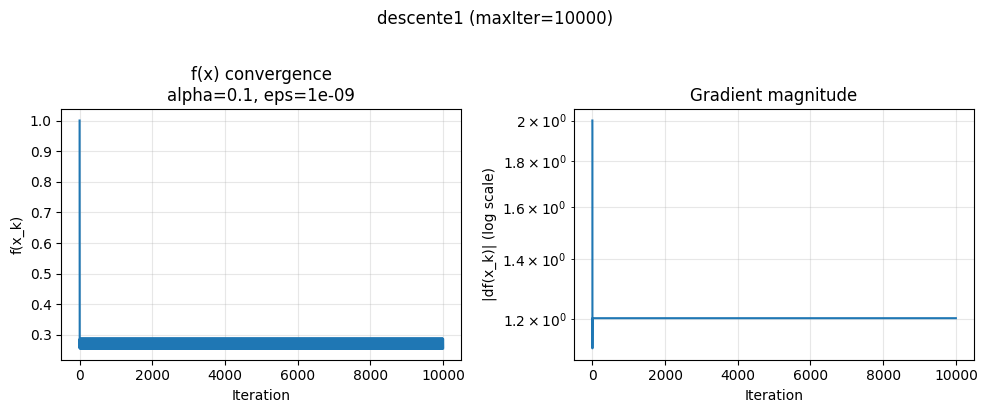

alpha=0.1, eps=1e-06, maxIter=1000 -> x=0.6145222499185753, f(x)=0.2875130113846983


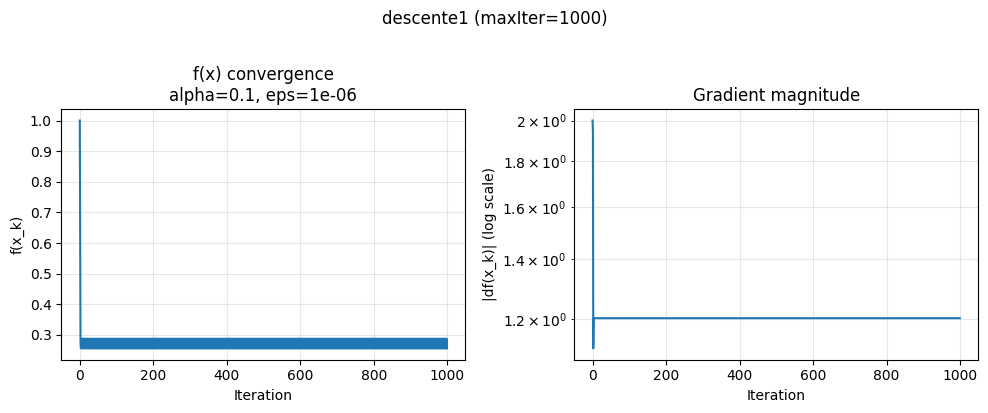

alpha=0.1, eps=1e-06, maxIter=5000 -> x=0.6145222499185753, f(x)=0.2875130113846983


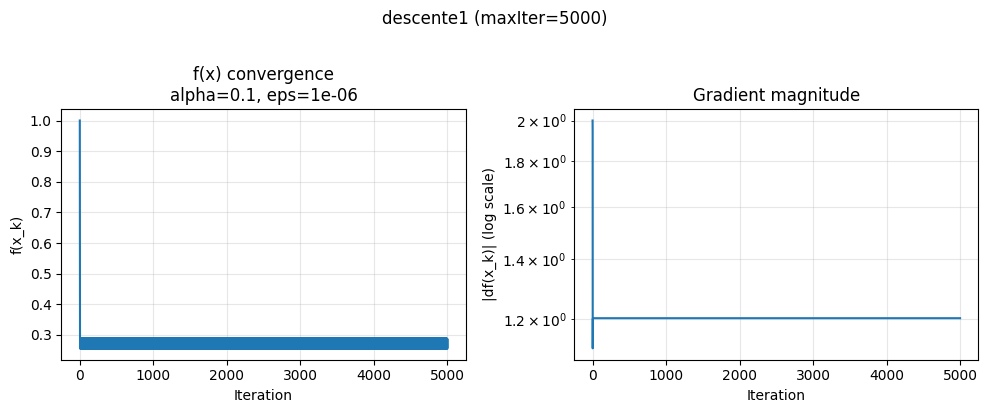

alpha=0.1, eps=1e-06, maxIter=10000 -> x=0.6145222499185753, f(x)=0.2875130113846983


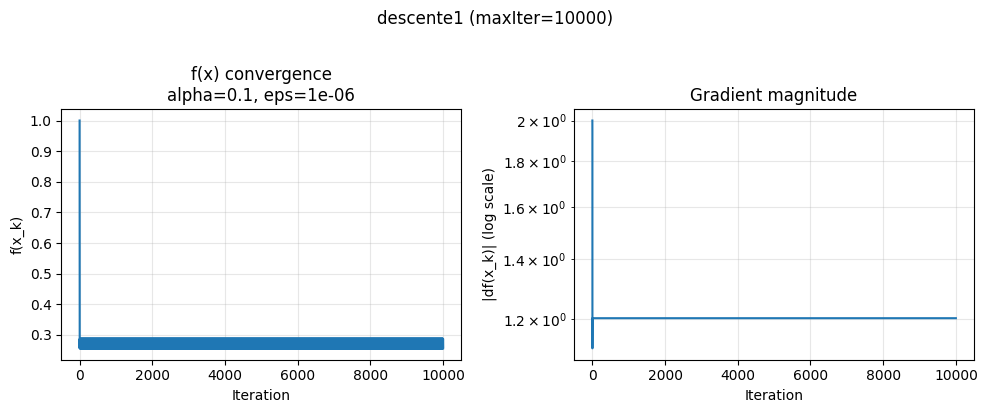

alpha=0.1, eps=0.001, maxIter=1000 -> x=0.6145222499185753, f(x)=0.2875130113846983


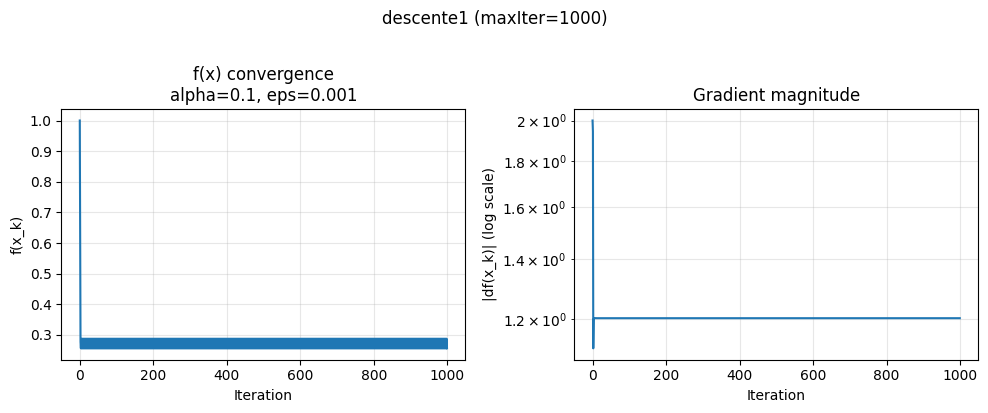

alpha=0.1, eps=0.001, maxIter=5000 -> x=0.6145222499185753, f(x)=0.2875130113846983


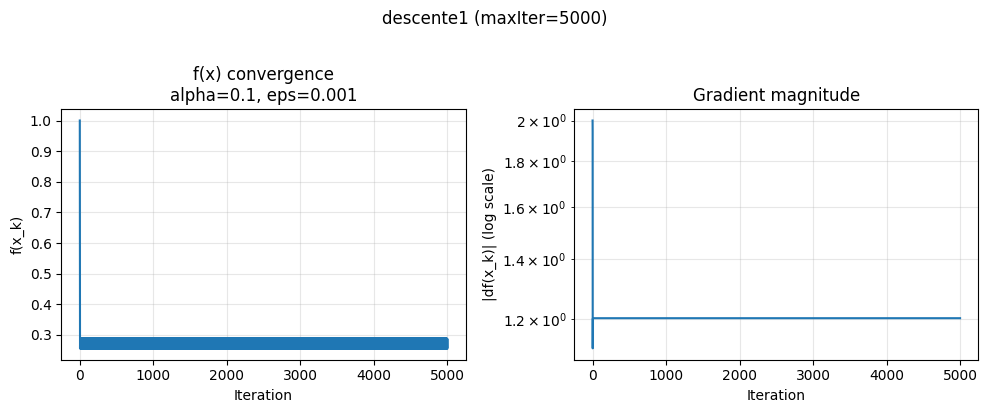

alpha=0.1, eps=0.001, maxIter=10000 -> x=0.6145222499185753, f(x)=0.2875130113846983


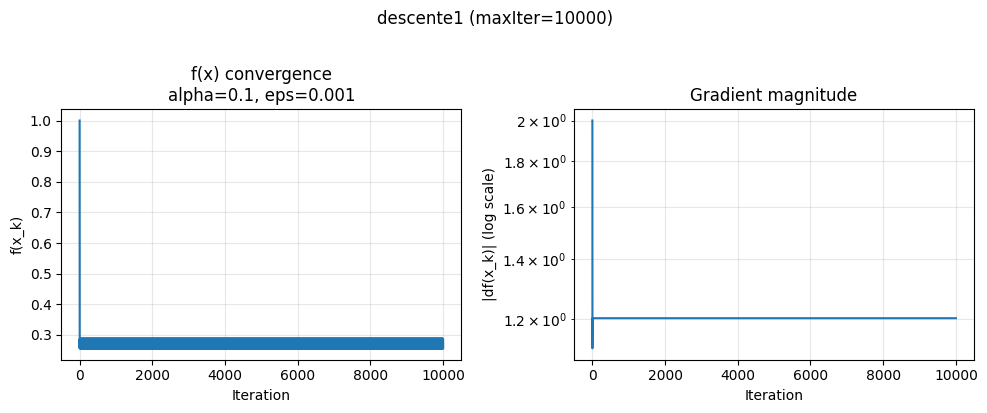

In [31]:
for alpha in alphas:
    for eps in epsilons:
        for maxIter in maxIters:
            x_star, hist = descente1_history(f, df, 1, alpha=alpha, eps=eps, maxIter=maxIter)
            fx = f(x_star)

            results.append((alpha, eps, maxIter, x_star, fx))
            print(f"alpha={alpha}, eps={eps}, maxIter={maxIter} -> x={x_star}, f(x)={fx}")

            # ---- plot convergence for this parameter set ----
            it = hist["it"]
            f_hist = hist["f"]
            gabs_hist = hist["gabs"]

            plt.figure(figsize=(10, 4))

            plt.subplot(1, 2, 1)
            plt.plot(it, f_hist)
            plt.xlabel("Iteration")
            plt.ylabel("f(x_k)")
            plt.grid(True, alpha=0.3)
            plt.title(f"f(x) convergence\nalpha={alpha}, eps={eps}")

            plt.subplot(1, 2, 2)
            plt.semilogy(it, gabs_hist)
            plt.xlabel("Iteration")
            plt.ylabel("|df(x_k)| (log scale)")
            plt.grid(True, which="both", alpha=0.3)
            plt.title("Gradient magnitude")

            plt.suptitle(f"descente1 (maxIter={maxIter})", y=1.02)
            plt.tight_layout()
            plt.show()

Now we used the forward difference in the descente 2 and we can see that the convergence is much slower than the central difference used in descente 1. This is because the forward difference is less accurate than the central difference, which leads to a less accurate estimate of the gradient and thus a slower convergence.


## Summary

what we ve try to do  in this homework is to implement two versions of gradient descent, one using the analytical gradient and the other using a numerical approximation of the gradient. We then compared their performance in terms of convergence to the minimum of a given function. We also experimented with different parameters such as learning rate, tolerance, and maximum iterations to see how they affect the convergence behavior. Finally, we visualized the convergence process for different parameter settings to better understand the optimization dynamics.

what I learned is that the choice of alpha and eps has a big effect on the convergence of the algorithm. If alpha is too small, the algorithm will take a long time to converge. If alpha is too large, the algorithm may diverge. If eps is too small, the algorithm may take a long time to converge. If eps is too large, the algorithm may stop before reaching a good solution.